In [1]:
# ============================================================
# Ice thickness core measurements (PISCES 2025)
# Satellite basemap + DAS cable + color-coded core thickness
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from pyproj import Geod

from das_tools import maps
from das_tools.utils import proj_path

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
# Everything is found through proj_path, so the notebook runs from any working
# directory and follows DAS_LFI_DATA_DIR / DAS_LFI_FIGURES_DIR if they are set.
#
# The satellite image and the EMI files are not tracked in git. Without the
# image the map is drawn on a plain background; without the core table or the
# EMI files the cells that need them are skipped.
ICE_CSV_PATH = proj_path.data_dir("ice_thickness", "IceThicknesses_PISCES2025_0430.csv")
EM_PATHS = sorted(proj_path.data_dir("ice_thickness").glob("EMthicknesses_*.csv"))
GEOTIFF_PATH = proj_path.data_dir("satellite", "sentinel2_2025-05-06_original.tif")
KML_PATH = proj_path.data_dir("CableRoute2025_onice_traced_smoothed.kml")

FIGURE_DIR = proj_path.figures_dir("supplementary", "S8_ice_drill_location", "figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUT_PDF = FIGURE_DIR / "ice_thickness_cores_map.pdf"
OUT_EMI_PDF = FIGURE_DIR / "emi_vs_drill_diff.pdf"

# ------------------------------------------------------------
# COLUMN NAMES IN THE CORE-MEASUREMENT CSV
# ------------------------------------------------------------
LAT_COL = "Latitude"
LON_COL = "Longitude"
THICK_COL = "Ice thickness measurement (m)"
DRAFT_COL = "Draft measurment (m)"
SNOW_COL = "Snow (m)"
NOTE_COL = "Location notes"
DATE_COL = "Date"

# ------------------------------------------------------------
# MAP APPEARANCE
# ------------------------------------------------------------
# ROI is fitted to the data (cores + cable) with this margin, in km.
ROI_MARGIN_KM = 0.35

# Set to numbers to override the color limits; None -> data range.
ICE_VMIN = None
ICE_VMAX = None

CMAP = "viridis"
MARKER_SIZE = 130

CABLE_COLOR = "red"
CABLE_LINEWIDTH = 3.0

LABEL_POINTS = True    # annotate each core with its row index
LABEL_FONTSIZE = 9

# ------------------------------------------------------------
# ORIENTED BOX AROUND A SUBSET OF CORES
# ------------------------------------------------------------
# Rows of `ice_df` the box has to enclose (indices as printed in cell 1).
BOX_IDX = list(range(9, 27))       # cores 7 ... 26

BOX_PAD_M = 250.0        # margin around the enclosed cores, in metres
BOX_COLOR = "black"
BOX_LINEWIDTH = 2.0
BOX_LINESTYLE = (0, (6, 4))

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

In [2]:
# ============================================================
# HELPERS
# ============================================================

def add_oriented_box(ax, x, y, pad=0.0, angle=None,
                     color="black", linewidth=2.0, linestyle=(0, (6, 4)),
                     zorder=20, label=None):
    """
    Minimum-area-style box around the points, rotated to their long axis.

    The orientation is the first principal component of (x, y) -- for cores
    strung along a straight cable leg that is the cable bearing. Pass
    `angle` (degrees CCW from +x) to force an orientation instead.
    `pad` widens the box on all four sides, in projected units (metres).

    Returns the Polygon patch.
    """
    from matplotlib.patches import Polygon

    p = np.column_stack([np.asarray(x, float), np.asarray(y, float)])
    ctr = p.mean(axis=0)

    if angle is None:
        # Principal axis of the point cloud.
        _, _, vt = np.linalg.svd(p - ctr, full_matrices=False)
        u = vt[0]
    else:
        a = np.deg2rad(angle)
        u = np.array([np.cos(a), np.sin(a)])

    v = np.array([-u[1], u[0]])            # cross-cable direction

    # Extents of the points in the rotated frame.
    su = (p - ctr) @ u
    sv = (p - ctr) @ v

    u0, u1 = su.min() - pad, su.max() + pad
    v0, v1 = sv.min() - pad, sv.max() + pad

    corners = np.array([
        ctr + u0 * u + v0 * v,
        ctr + u1 * u + v0 * v,
        ctr + u1 * u + v1 * v,
        ctr + u0 * u + v1 * v,
    ])

    patch = Polygon(corners, closed=True, fill=False,
                    edgecolor=color, linewidth=linewidth,
                    linestyle=linestyle, zorder=zorder, label=label)
    ax.add_patch(patch)
    return patch


def add_index_labels(ax, x, y, labels, fontsize=9, marker_size=130,
                     color="black", halo="white", leader_color="0.25",
                     radii=(12, 19, 29, 41, 55, 72), n_angles=16,
                     start_angle=45.0, leader_min_px=13.0, pad_px=1.5):
    """
    Annotate scatter points with non-overlapping text labels.

    Each label is tried at a series of candidate offsets on rings of
    increasing radius around its marker; the first candidate that clears
    every previously placed label and every marker is kept. Labels pushed
    beyond `leader_min_px` get a thin leader line back to their point.

    Works in display (pixel) space, so it must run after the axes limits
    are final. Returns the list of Annotation objects.
    """
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Marker footprints are obstacles: s is in points^2.
    r_marker = 0.5 * np.sqrt(marker_size) * fig.dpi / 72.0
    px, py = ax.transData.transform(np.column_stack([x, y])).T

    obstacles = [
        (cx - r_marker, cy - r_marker, cx + r_marker, cy + r_marker)
        for cx, cy in zip(px, py)
    ]

    ax_bb = ax.get_window_extent(rend)

    def overlaps(a, b):
        return not (a[2] <= b[0] or a[0] >= b[2] or a[3] <= b[1] or a[1] >= b[3])

    # Candidate offsets, nearest ring first, angles fanning out from start.
    angles = np.deg2rad(start_angle + np.arange(n_angles) * 360.0 / n_angles)
    candidates = [(0.0, 0.0)] if 0 in radii else []
    for r in [r for r in radii if r > 0]:
        for a in angles:
            candidates.append((r * np.cos(a), r * np.sin(a)))

    anns = []

    for i, lab in enumerate(labels):

        ann = ax.annotate(
            str(lab), (x[i], y[i]),
            xytext=(r_marker + 3, r_marker + 3), textcoords="offset points",
            fontsize=fontsize, color=color, zorder=12,
            ha="center", va="center", annotation_clip=False,
        )
        ann.set_path_effects([pe.Stroke(linewidth=2.0, foreground=halo),
                              pe.Normal()])

        # Own marker must not block its own label.
        others = obstacles[:i] + obstacles[i + 1:]

        best = None
        for dx, dy in candidates:
            # Offsets are in points; convert the pixel radius accordingly.
            ann.set_position((dx * 72.0 / fig.dpi, dy * 72.0 / fig.dpi))
            bb = ann.get_window_extent(rend)
            box = (bb.x0 - pad_px, bb.y0 - pad_px, bb.x1 + pad_px, bb.y1 + pad_px)

            inside = (box[0] >= ax_bb.x0 and box[2] <= ax_bb.x1
                      and box[1] >= ax_bb.y0 and box[3] <= ax_bb.y1)

            if not inside:
                continue
            if any(overlaps(box, o) for o in others):
                continue

            best = (dx, dy, box)
            break

        if best is None:
            # Nothing clear anywhere: fall back to the outermost ring.
            dx, dy = candidates[-1]
            ann.set_position((dx * 72.0 / fig.dpi, dy * 72.0 / fig.dpi))
            bb = ann.get_window_extent(rend)
            best = (dx, dy, (bb.x0, bb.y0, bb.x1, bb.y1))

        dx, dy, box = best
        ann.set_position((dx * 72.0 / fig.dpi, dy * 72.0 / fig.dpi))

        # Reserve the space so later labels avoid it.
        obstacles.append(box)

        # Leader line for labels that had to move far from their marker.
        if np.hypot(dx, dy) > leader_min_px:
            ax.annotate(
                "", xy=(x[i], y[i]), xycoords="data",
                xytext=(dx * 72.0 / fig.dpi, dy * 72.0 / fig.dpi),
                textcoords="offset points",
                arrowprops=dict(arrowstyle="-", color=leader_color,
                                linewidth=0.8, shrinkA=2, shrinkB=r_marker * 0.9),
                zorder=11,
            )

        anns.append(ann)

    return anns

In [3]:
# ============================================================
# 1. READ THE ICE-CORE MEASUREMENTS
# ============================================================

TABLE_COLS = [DATE_COL, LAT_COL, LON_COL, DRAFT_COL, THICK_COL, SNOW_COL, NOTE_COL]

if ICE_CSV_PATH.is_file():
    # utf-8-sig strips the BOM on the first header field.
    ice_df = pd.read_csv(ICE_CSV_PATH, encoding="utf-8-sig")

    # Drop trailing blank rows / rows without a position or a thickness.
    ice_df = ice_df.dropna(subset=[LAT_COL, LON_COL, THICK_COL]).reset_index(drop=True)
else:
    print(f"No core table at {ICE_CSV_PATH}; the map shows the cable only.")
    ice_df = pd.DataFrame(columns=TABLE_COLS)

HAVE_ICE = len(ice_df) > 0

lat_ice = ice_df[LAT_COL].to_numpy(dtype=float)
lon_ice = ice_df[LON_COL].to_numpy(dtype=float)
TT = ice_df[THICK_COL].to_numpy(dtype=float)

if HAVE_ICE:
    print(f"{len(ice_df)} core measurements read from {ICE_CSV_PATH.name}")
    print(f"thickness: min {TT.min():.2f} m, max {TT.max():.2f} m, mean {TT.mean():.2f} m")

# Index table -- use these indices in the statistics cell below.
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

ice_df[TABLE_COLS]

27 core measurements read from IceThicknesses_PISCES2025_0430.csv
thickness: min 0.87 m, max 1.62 m, mean 1.10 m


,Date,Latitude,Longitude,Draft measurment (m),Ice thickness measurement (m),Snow (m),Location notes
0,4/19/25,71.348314,-156.701899,0.83,0.87,NaN,NaN
1,4/19/25,71.345880,-156.693130,1.16,1.29,NaN,NaN
2,4/19/25,71.344260,-156.682110,1.08,1.15,NaN,NaN
3,4/19/25,71.353260,-156.681410,0.89,0.95,NaN,NaN
4,4/19/25,71.343390,-156.670330,1.47,1.62,NaN,NaN
5,4/19/25,71.339780,-156.665790,1.41,1.32,NaN,NaN
6,4/21/25,71.349444,-156.658502,1.35,1.45,NaN,Seismic station #3 (WP #114)
7,4/21/25,71.345219,-156.673884,1.00,1.09,0.02,Seismic station #2 (WP #115)
8,4/21/25,71.339224,-156.663640,1.32,1.44,0.08,Seismic station #1 (WP #116)
9,4/24/25,71.344985,-156.674368,0.96,1.02,0.10,Hydrophone horizontal array #5 (WP #121)


In [4]:
# ============================================================
# 2. READ THE CABLE AND DEFINE THE ROI
# ============================================================

lon_cab, lat_cab = maps.read_kml_lonlat(KML_PATH)

# Fit the ROI to everything we want to show (cores + cable), plus a margin.
lon_min, lon_max, lat_min, lat_max = maps.points_box(
    np.r_[lon_ice, lon_cab], np.r_[lat_ice, lat_cab], pad_km=ROI_MARGIN_KM)

print(f"ROI longitude: {lon_min:.6f} to {lon_max:.6f}")
print(f"ROI latitude : {lat_min:.6f} to {lat_max:.6f}")


# ============================================================
# 3. READ AND CROP THE SATELLITE IMAGE
# ============================================================

bm = maps.load_basemap(GEOTIFF_PATH, lon_min, lon_max, lat_min, lat_max, stretch=(0, 98))

# Project cable and cores into the satellite CRS.
x_cab, y_cab = bm.xy(lon_cab, lat_cab)
x_ice, y_ice = bm.xy(lon_ice, lat_ice)

print("satellite CRS:", bm.crs)

ROI longitude: -156.711728 to -156.648075
ROI latitude : 71.331407 to 71.356425
satellite CRS: EPSG:3857


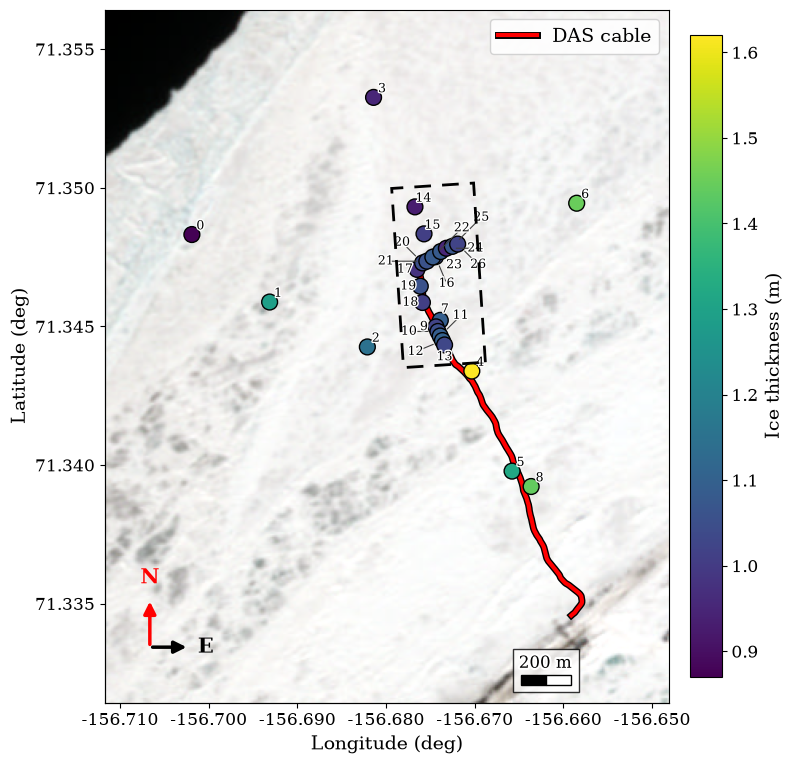

In [5]:
# ============================================================
# 4. PLOT: SATELLITE + CABLE + COLOR-CODED CORE THICKNESS
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

bm.show(ax)

# DAS cable
ax.plot(
    x_cab, y_cab,
    color=CABLE_COLOR,
    linewidth=CABLE_LINEWIDTH,
    zorder=5,
    label="DAS cable",
    path_effects=maps.halo(CABLE_LINEWIDTH + 2, "black"),
)

if HAVE_ICE:
    vmin = TT.min() if ICE_VMIN is None else ICE_VMIN
    vmax = TT.max() if ICE_VMAX is None else ICE_VMAX

    # Ice-thickness cores
    sc = ax.scatter(
        x_ice, y_ice,
        c=TT,
        vmin=vmin, vmax=vmax,
        cmap=CMAP,
        s=MARKER_SIZE,
        marker="o",
        edgecolors="black",
        linewidths=1.0,
        zorder=10,
    )

    # Dashed box around cores BOX_IDX, rotated onto the long cable leg.
    box_idx = [i for i in BOX_IDX if i < len(ice_df)]
    if len(box_idx) >= 2:
        add_oriented_box(
            ax,
            x_ice[box_idx], y_ice[box_idx],
            pad=BOX_PAD_M,
            color=BOX_COLOR,
            linewidth=BOX_LINEWIDTH,
            linestyle=BOX_LINESTYLE,
            zorder=20,
            label=None,
        )

maps.add_ne_arrows(ax, x0=0.08, y0=0.08, mutation_scale=18, fontsize=15)
maps.add_scalebar(ax, bm, 200, corner="lower right", pad=(0.17, 0.025), fontsize=12)

# Lat/lon ticks; must come before the labels, which need the final layout.
maps.add_lonlat_axes(ax, bm, lon_step=0.01, lat_step=0.005, lon_decimals=3, lat_decimals=3,
                     rotate_lat_labels=False)

# Row-index labels next to each core (indices match the table in cell 1).
if HAVE_ICE and LABEL_POINTS:
    add_index_labels(
        ax, x_ice, y_ice, ice_df.index,
        fontsize=LABEL_FONTSIZE,
        marker_size=MARKER_SIZE,
    )

leg = ax.legend(loc="upper right", framealpha=0.85)
leg.set_zorder(30)

if HAVE_ICE:
    cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label("Ice thickness (m)")

fig.savefig(OUT_PDF, dpi=300, bbox_inches="tight")
plt.show()